# 05 — Controlled $100 response-contamination stress test

This experiment illustrates the robustness property of LTS from ED409 Module
II. It is not an attempt to claim that genuine taxi records are corrupted.

Exactly 2,000 of 40,000 training rows (5%) were selected without replacement
using seed 42. Exactly $100 was added to their fare responses. Predictors and
the entire 10,000-row clean test set remained unchanged. Clean and contaminated
models use the same training-fitted scaling and are evaluated on the same clean
test observations.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
TABLES = PROJECT_ROOT / "outputs/tables"
metadata = json.loads((PROJECT_ROOT / "outputs/contamination_metadata.json").read_text())
display(pd.Series(metadata, name="Value").to_frame())

,Value
scope,controlled training-response contamination
training_observations,40000
test_observations,10000
contaminated_training_observations,2000
contamination_fraction,0.05
fare_addition_usd,100.0
seed,42
alpha,0.75
initial_subsets,500
test_set_unchanged,True


## 1. Experimental design

Only the response is altered:

\[
y_i^{*}=y_i+100 \quad\text{for selected training rows}.
\]

This is vertical response contamination. It does not create high-leverage
predictor values. OLS minimizes all squared residuals, whereas raw LTS at
`alpha = 0.75` minimizes the 30,000 smallest squared residuals. The clean fit
was frozen before the contaminated fit was examined.

## 2. Clean-test performance degradation

The test set remains clean. Any change in its performance is therefore caused
by learning from the contaminated training response, not by changing the
evaluation data.

,training_scenario,estimator,mae,rmse,median_absolute_error,r_squared
0,clean,OLS,2.086,3.253,1.594,0.923
1,clean,Reweighted LTS,1.015,8.756,0.347,0.445
2,contaminated,OLS,5.383,5.939,5.578,0.745
3,contaminated,Reweighted LTS,1.000,8.737,0.347,0.448


,estimator,clean_mae,contaminated_mae,change_mae,clean_rmse,contaminated_rmse,change_rmse,clean_median_absolute_error,contaminated_median_absolute_error,change_median_absolute_error,clean_r_squared,contaminated_r_squared,change_r_squared
0,OLS,2.086,5.383,3.297,3.253,5.939,2.686,1.594,5.578,3.984,0.923,0.745,-0.179
1,Reweighted LTS,1.015,1.000,-0.015,8.756,8.737,-0.019,0.347,0.347,0.000,0.445,0.448,0.002


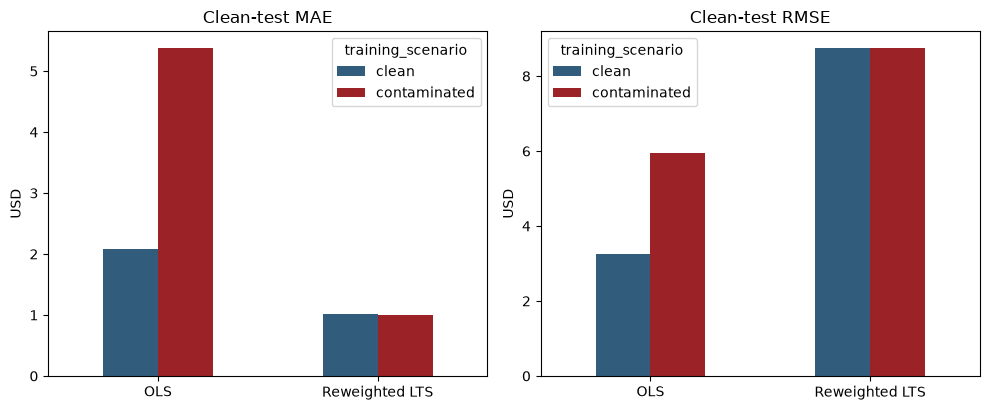

In [2]:
performance = pd.read_csv(TABLES / "contamination_model_performance.csv")
degradation = pd.read_csv(TABLES / "contamination_prediction_degradation.csv")
display(performance.style.format(precision=3))
display(degradation.style.format(precision=3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for axis, metric in zip(axes, ["mae", "rmse"], strict=True):
    pivot = performance.pivot(index="estimator", columns="training_scenario", values=metric)
    pivot.plot.bar(ax=axis, color=["#315C7C", "#9B2226"])
    axis.set(title=f"Clean-test {metric.upper()}", ylabel="USD", xlabel="")
    axis.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### Interpretation

After contamination, OLS test MAE rises from $2.09 to $5.38 and RMSE from
$3.25 to $5.94; R-squared falls from 0.923 to 0.745. Reweighted LTS is stable:
MAE changes from $1.015 to $1.000 and RMSE from $8.756 to $8.737. The tiny LTS
improvement is sampling variation, not evidence that contamination helps.

This experiment demonstrates resistance: LTS preserves almost the same fitted
relationship when a minority of training responses is shifted severely.

## 3. Coefficient stability

Coefficient change is calculated in original predictor units. Percent changes
for coefficients already near zero can look large, so absolute changes and the
substantively important intercept, distance, and duration slopes should receive
more attention.

,estimator,term,clean,contaminated,absolute_change,absolute_change_magnitude,percent_change_from_clean
0,OLS,const,5.2406,10.0672,4.8266,4.8266,92.1001
1,OLS,duration_min,0.0824,0.0768,-0.0056,0.0056,-6.7742
2,OLS,is_weekend,-0.7448,-0.7966,-0.0518,0.0518,-6.9484
3,OLS,passenger_count,0.1380,0.1646,0.0266,0.0266,19.2738
4,OLS,pickup_hour_cos,-1.0891,-1.2942,-0.2050,0.2050,-18.8262
5,OLS,pickup_hour_sin,-0.5781,-0.7317,-0.1536,0.1536,-26.5681
6,OLS,trip_distance,3.6218,3.6774,0.0557,0.0557,1.5367
7,Reweighted LTS,const,2.4025,2.3780,-0.0245,0.0245,-1.0209
8,Reweighted LTS,duration_min,0.6050,0.6045,-0.0005,0.0005,-0.0896
9,Reweighted LTS,is_weekend,-0.0115,-0.0123,-0.0008,0.0008,-7.0587


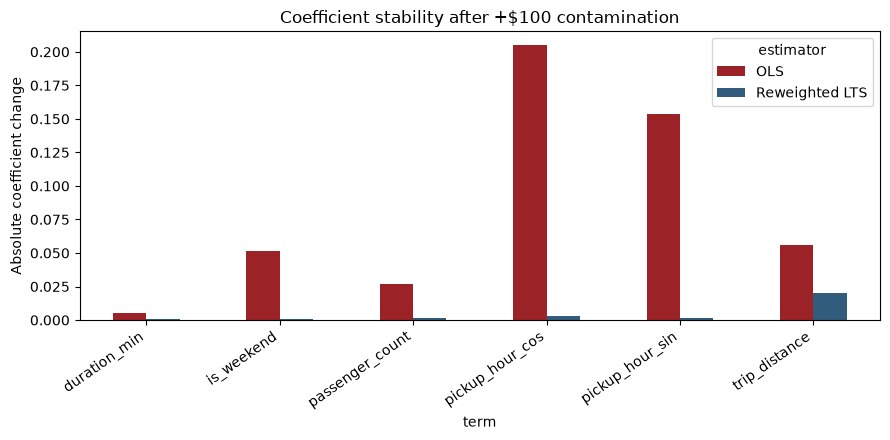

In [3]:
coefficient_change = pd.read_csv(TABLES / "contamination_coefficient_change.csv")
display(coefficient_change.style.format(precision=4))

slopes = coefficient_change.loc[coefficient_change["term"].ne("const")]
pivot = slopes.pivot(index="term", columns="estimator", values="absolute_change_magnitude")
pivot.plot.bar(figsize=(9, 4.5), color=["#9B2226", "#315C7C"])
plt.ylabel("Absolute coefficient change")
plt.title("Coefficient stability after +$100 contamination")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

The OLS intercept increases by $4.83, close to the unconditional mean shift
`0.05 × $100 = $5`. Several OLS time and weekend coefficients also move.
Reweighted LTS's intercept changes by only $0.025, its distance slope by about
$0.020 per mile, and its duration slope by about $0.0005 per minute.

## 4. Known-contamination detection

Primary LTS flags rows receiving zero reweighting weight or absolute robust
standardized residual above 2.5. Because the artificial rows are known, recall
and precision can be calculated exactly.

In [4]:
detection = pd.read_csv(TABLES / "contamination_detection_summary.csv")
detail = pd.read_csv(TABLES / "contamination_detection_detail.csv")
display(detection.style.format(precision=4))
display(detail.loc[detail["known_artificial_contamination"]].head(15).style.format(precision=3))

,training_observations,known_contaminated,flagged_total,true_positive,false_positive,false_negative,true_negative,detection_recall,detection_precision,false_positive_rate,raw_mad_scale,reweighting_cutoff,audit_residual_cutoff
0,40000,2000,7684,2000,5684,0,32316,1.0000,0.2603,0.1496,0.5533,2.2414,2.5000


,modeling_row_id,source_row_id,pickup_datetime,dropoff_datetime,original_fare_amount,trip_distance,duration_min,passenger_count,pickup_hour_sin,pickup_hour_cos,is_weekend,experimental_fare_amount,known_artificial_contamination,raw_lts_standardized_robust_residual,zero_reweight_flag,absolute_standardized_residual_above_2_5,audit_candidate,detection_class,absolute_standardized_residual
0,41538,37137,2026-01-01 14:01:03,2026-01-01 14:59:09,126.900,33.510,58.100,1.000,-0.500,-0.866,0,226.900,True,232.336,True,True,True,true_positive,232.336
1,10059,1195569,2026-01-15 01:06:40,2026-01-15 01:47:37,98.200,26.810,40.950,1.000,0.259,0.966,0,198.200,True,221.145,True,True,True,true_positive,221.145
2,44090,1802123,2026-01-21 19:15:41,2026-01-21 20:18:51,105.200,25.380,63.167,2.000,-0.966,0.259,0,205.200,True,214.319,True,True,True,true_positive,214.319
3,41574,2118288,2026-01-24 22:04:53,2026-01-24 22:41:34,82.800,22.270,36.683,4.000,-0.500,0.866,1,182.800,True,212.884,True,True,True,true_positive,212.884
4,42731,56917,2026-01-01 19:42:50,2026-01-01 20:16:47,78.600,21.110,33.950,1.000,-0.966,0.259,0,178.600,True,212.178,True,True,True,true_positive,212.178
5,43984,1309807,2026-01-16 07:28:39,2026-01-16 08:28:06,98.200,24.500,59.450,2.000,0.966,-0.259,0,198.200,True,208.373,True,True,True,true_positive,208.373
6,10005,139658,2026-01-02 23:19:35,2026-01-02 23:55:50,74.400,19.250,36.250,4.000,-0.259,0.966,0,174.400,True,208.037,True,True,True,true_positive,208.037
7,46649,540577,2026-01-07 23:51:12,2026-01-08 00:31:23,73.700,18.180,40.183,1.000,-0.259,0.966,0,173.700,True,206.071,True,True,True,true_positive,206.071
8,21753,1418339,2026-01-17 10:30:47,2026-01-17 11:07:11,70.200,17.480,36.400,1.000,0.500,-0.866,1,170.200,True,206.044,True,True,True,true_positive,206.044
9,35098,1572200,2026-01-19 10:22:18,2026-01-19 10:57:41,69.500,17.800,35.383,4.000,0.500,-0.866,0,169.500,True,204.734,True,True,True,true_positive,204.734


LTS flags all 2,000 artificial corruptions: recall is 100% and there are no
false negatives. It also flags 5,684 unaltered training rows, so precision is
26.0% and the false-positive rate is about 15.0%.

This does not mean the additional rows are statistical mistakes. They may be
rare tariffs, recording problems, omitted route effects, or legitimate unusual
trips. The result supports using LTS flags for **audit prioritization**, not
automatic fraud classification.

## 5. What the fitted relationships are doing

PCA is not used for these plots. PCA ignores fare when constructing components,
and a line against the first component would not faithfully represent either
six-predictor regression. Instead, the reference-profile plots vary one
predictor while holding the others at a valid stated trip. The response-surface
plots vary distance and duration together while fixing one passenger, weekday,
and noon.

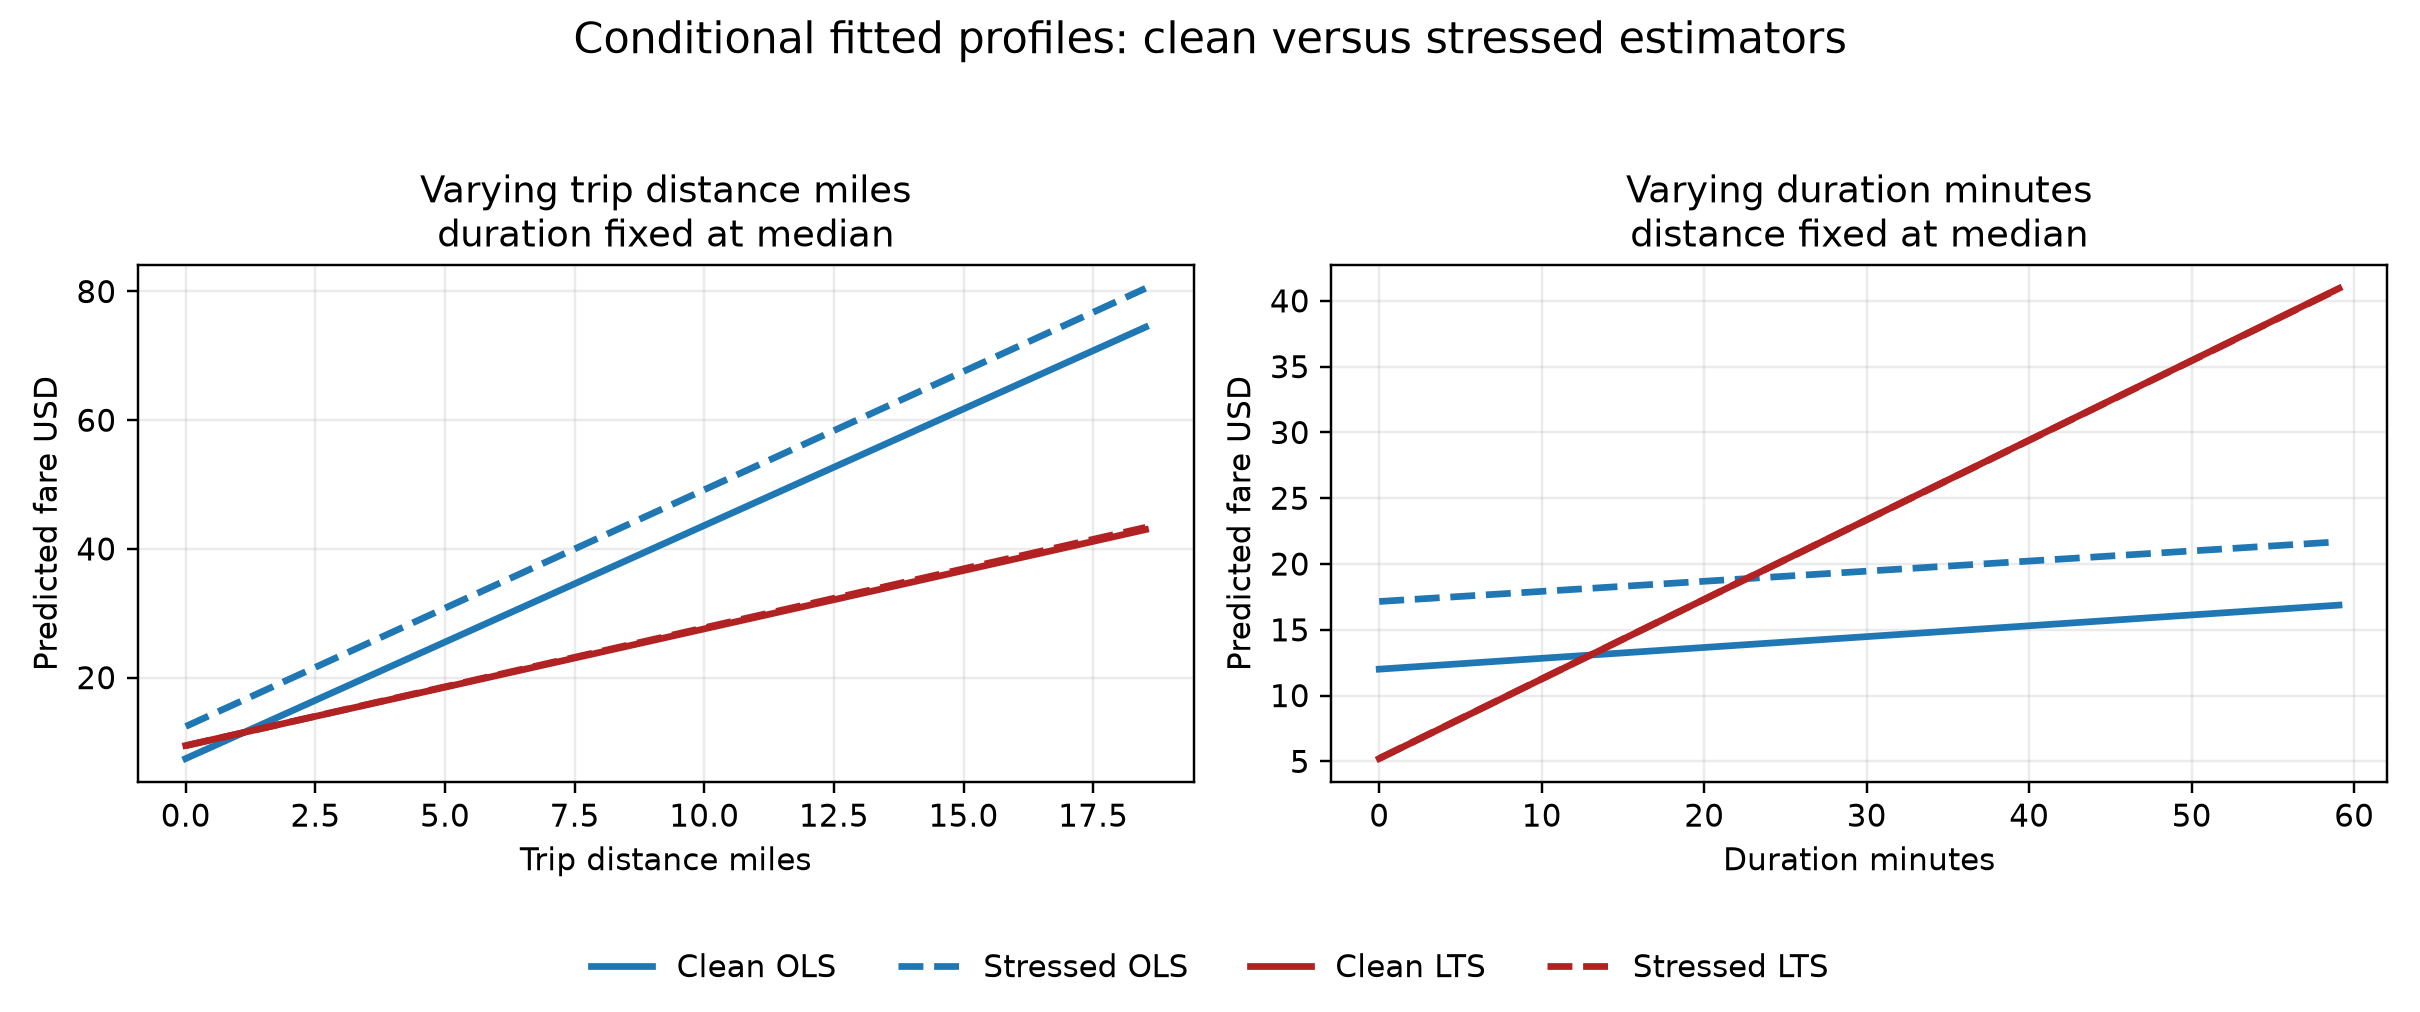

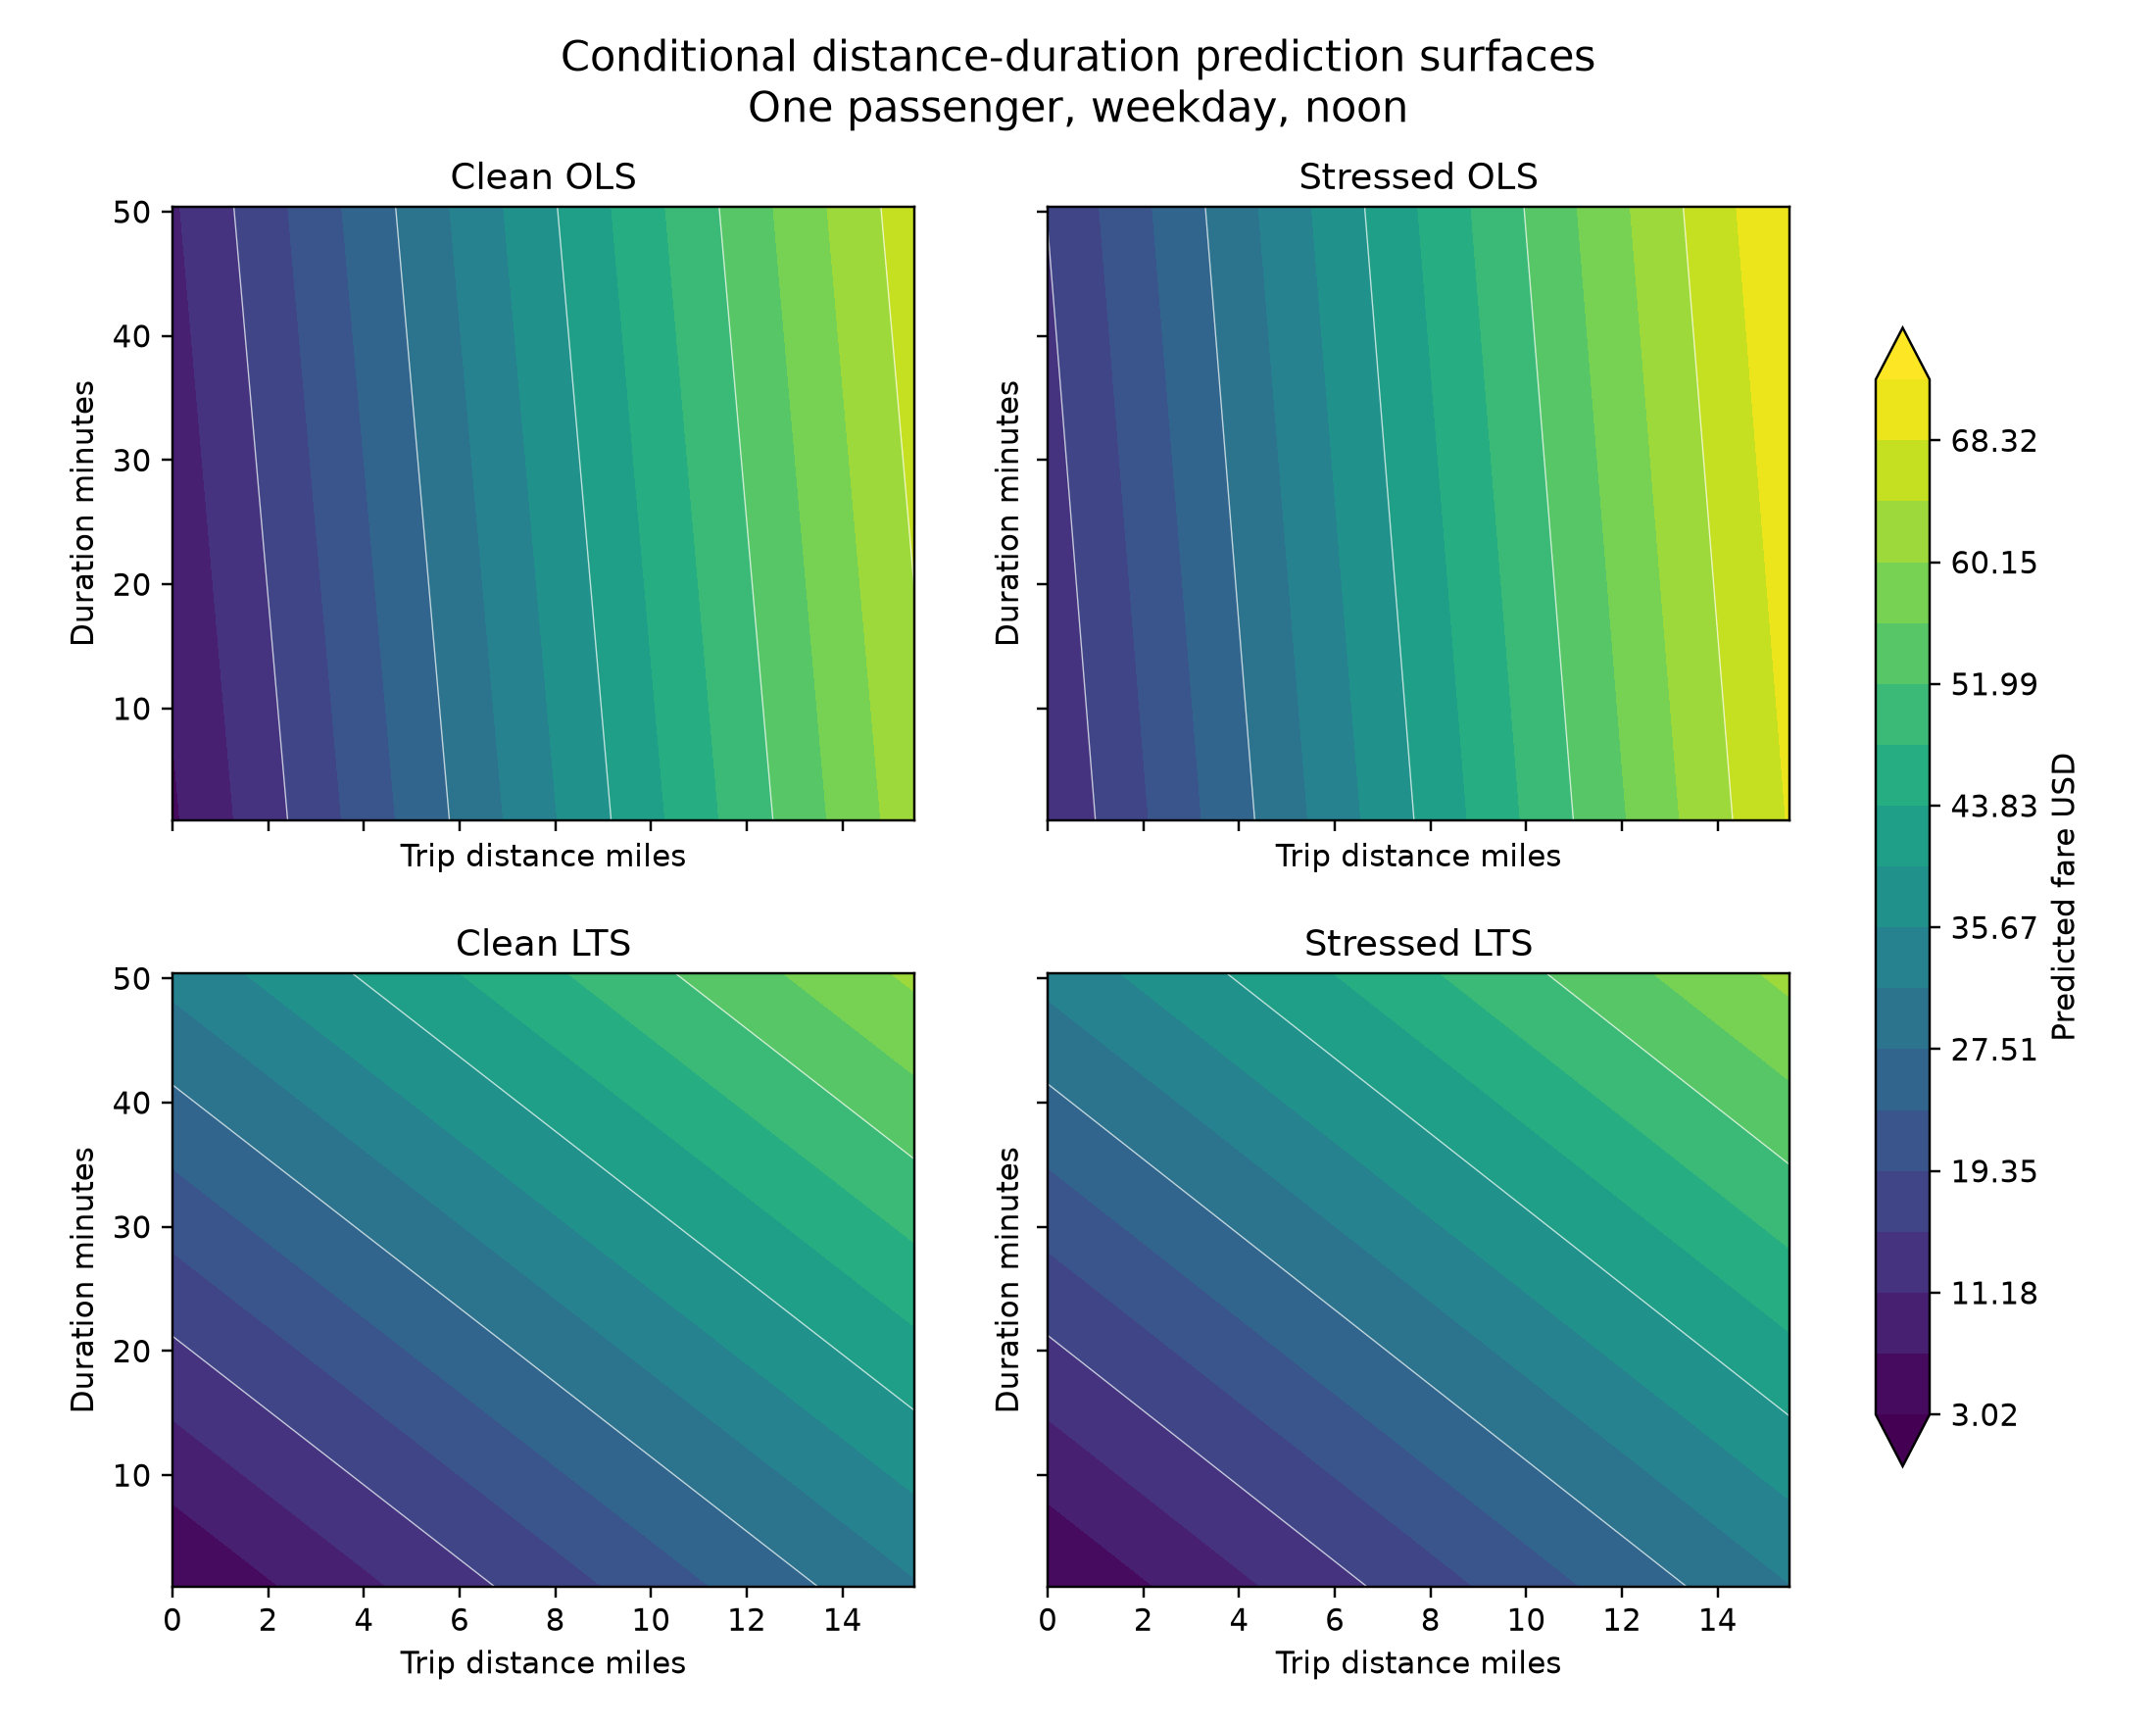

In [5]:
from IPython.display import Image

display(Image(filename=PROJECT_ROOT / "outputs/figures/clean_stress_fitted_profiles.png"))
display(Image(filename=PROJECT_ROOT / "outputs/figures/clean_stress_prediction_surfaces.png"))

The solid and dashed LTS profiles nearly overlap, directly displaying its
stability under contamination. The stressed OLS profile shifts upward, mainly
through the intercept increase. The surfaces also reveal the deeper clean-data
difference: OLS places much greater weight on distance, while LTS follows a
joint distance-duration tariff-like plane.

## Presentation statement

> Under a controlled 5% +$100 response shift, OLS coefficients and clean-test
> predictions deteriorated substantially. Reweighted LTS preserved its clean
> relationship and detected every artificial corruption. However, its broad
> audit screen had low precision because many genuine unusual trips were also
> incompatible with the dominant relationship.